In [1]:
# 1 - import
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
# 2 - load data
df = pd.read_csv("diabetes_prediction_dataset.csv")

In [3]:
# 3 - inspect data
display(df.head())

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
# 4 - data overview
print("Shape:", df.shape)
df.info()

Shape: (100000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [5]:
# 5 - check data
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Duplicate rows: 3854


In [6]:
# 6 - statistics
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


In [7]:
# 7 - preprocess
df = df.drop_duplicates().reset_index(drop=True)
df["gender"] = df["gender"].astype(str).str.lower().str.strip()
df["smoking_history"] = df["smoking_history"].astype(str).str.lower().str.strip()

In [8]:
# 8 - create documents
documents = [
    f"Record {i}: gender {r.gender}, age {r.age}, hypertension {r.hypertension}, "
    f"heart disease {r.heart_disease}, smoking history {r.smoking_history}, "
    f"BMI {r.bmi}, HbA1c level {r.HbA1c_level}, blood glucose level {r.blood_glucose_level}, "
    f"diabetes {r.diabetes}."
    for i, r in df.iterrows()
]
print(documents[:3])

['Record 0: gender female, age 80.0, hypertension 0, heart disease 1, smoking history never, BMI 25.19, HbA1c level 6.6, blood glucose level 140, diabetes 0.', 'Record 1: gender female, age 54.0, hypertension 0, heart disease 0, smoking history no info, BMI 27.32, HbA1c level 6.6, blood glucose level 80, diabetes 0.', 'Record 2: gender male, age 28.0, hypertension 0, heart disease 0, smoking history never, BMI 27.32, HbA1c level 5.7, blood glucose level 158, diabetes 0.']


In [9]:
# 9 - create knowledge base
knowledge_base = pd.DataFrame({
    "record_id": range(len(df)),
    "document": documents
})
display(knowledge_base.head())

,record_id,document
0,0,"Record 0: gender female, age 80.0, hypertensio..."
1,1,"Record 1: gender female, age 54.0, hypertensio..."
2,2,"Record 2: gender male, age 28.0, hypertension ..."
3,3,"Record 3: gender female, age 36.0, hypertensio..."
4,4,"Record 4: gender male, age 76.0, hypertension ..."


In [10]:
# 10 - create triples
triples = [
    (f"Person_{i}", "has_gender", str(r["gender"]))
    for i, r in df.iterrows()
]
triples += [
    (f"Person_{i}", "has_diabetes", str(r["diabetes"]))
    for i, r in df.iterrows()
]
triples += [
    (f"Person_{i}", "has_smoking_history", str(r["smoking_history"]))
    for i, r in df.iterrows()
]
print(triples[:10])

[('Person_0', 'has_gender', 'female'), ('Person_1', 'has_gender', 'female'), ('Person_2', 'has_gender', 'male'), ('Person_3', 'has_gender', 'female'), ('Person_4', 'has_gender', 'male'), ('Person_5', 'has_gender', 'female'), ('Person_6', 'has_gender', 'female'), ('Person_7', 'has_gender', 'female'), ('Person_8', 'has_gender', 'male'), ('Person_9', 'has_gender', 'female')]


In [11]:
# 11 - build knowledge graph
G = nx.DiGraph()
for subject, relation, obj in triples:
    G.add_edge(subject, obj, relation=relation)
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

Nodes: 96157 | Edges: 288438


In [12]:
# 12 - graph query
diabetes_counts = df["diabetes"].value_counts()
display(diabetes_counts)

diabetes
0    87664
1     8482
Name: count, dtype: int64

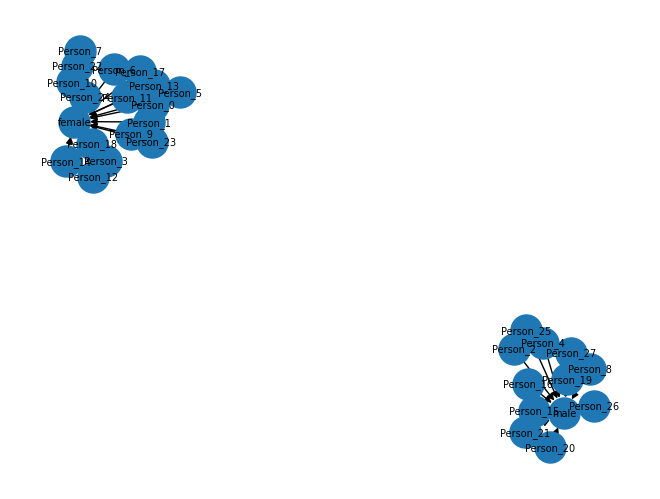

In [13]:
# 13 - visualize graph
sub_nodes = list(G.nodes)[:30]
nx.draw(G.subgraph(sub_nodes), with_labels=True, node_size=500, font_size=7)
plt.show()

In [14]:
# 14 - build tfidf index
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(knowledge_base["document"])

In [15]:
# 15 - retrieve documents
def retrieve_tfidf(query, k=3):
    query_vector = tfidf.transform([query])
    scores = cosine_similarity(query_vector, tfidf_matrix).flatten()
    indices = scores.argsort()[::-1][:k]
    return [(int(i), float(scores[i]), knowledge_base.iloc[i]["document"]) for i in indices]

In [16]:
# 16 - test retrieval
for record_id, score, document in retrieve_tfidf("people with high blood glucose and diabetes", 3):
    print(f"ID: {record_id} | Score: {score:.4f}\n{document}\n")

ID: 2 | Score: 0.2181
Record 2: gender male, age 28.0, hypertension 0, heart disease 0, smoking history never, BMI 27.32, HbA1c level 5.7, blood glucose level 158, diabetes 0.

ID: 9 | Score: 0.2176
Record 9: gender female, age 32.0, hypertension 0, heart disease 0, smoking history never, BMI 27.32, HbA1c level 5.0, blood glucose level 100, diabetes 0.

ID: 5 | Score: 0.2163
Record 5: gender female, age 20.0, hypertension 0, heart disease 0, smoking history never, BMI 27.32, HbA1c level 6.6, blood glucose level 85, diabetes 0.



In [17]:
# 17 - install embedding library
%pip install sentence-transformers

   ---------------------------------------- 0.0/740.6 kB ? eta -:--:--
   ---------------------------- ----------- 524.3/740.6 kB 5.2 MB/s eta 0:00:01
   ---------------------------------------- 740.6/740.6 kB 4.5 MB/s  0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   -------------- ------------------------- 4.5/12.6 MB 22.8 MB/s eta 0:00:01
   ------------------------ --------------- 7.6/12.6 MB 21.5 MB/s eta 0:00:01
   ---------------------------------- ----- 11.0/12.6 MB 17.9 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 15.7 MB/s  0:00:00
   ---------------------------------------- 0.0/846.4 kB ? eta -:--:--
   ---------------------------------------- 846.4/846.4 kB 12.5 MB/s  0:00:00
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ---------------------------------------- 3.8/3.8 MB 87.0 MB/s  0:00:00
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
# 18 - create embeddings
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(documents, show_progress_bar=True, normalize_embeddings=True)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\vuthu\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\vuthu\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/3005 [00:00<?, ?it/s]

In [19]:
# 19 - semantic retrieval
def retrieve_semantic(query, k=3):
    query_embedding = embedding_model.encode([query], normalize_embeddings=True)
    scores = embeddings @ query_embedding[0]
    indices = scores.argsort()[::-1][:k]
    return [(int(i), float(scores[i]), documents[i]) for i in indices]

In [20]:
# 20 - test semantic retrieval
for record_id, score, document in retrieve_semantic("Which records show diabetes and elevated glucose?", 3):
    print(f"ID: {record_id} | Similarity: {score:.4f}\n{document}\n")

ID: 17160 | Similarity: 0.5785
Record 17160: gender female, age 80.0, hypertension 1, heart disease 1, smoking history never, BMI 27.32, HbA1c level 6.1, blood glucose level 130, diabetes 0.

ID: 1731 | Similarity: 0.5714
Record 1731: gender female, age 32.0, hypertension 0, heart disease 0, smoking history no info, BMI 27.32, HbA1c level 6.6, blood glucose level 85, diabetes 0.

ID: 17215 | Similarity: 0.5689
Record 17215: gender female, age 64.0, hypertension 0, heart disease 0, smoking history never, BMI 44.08, HbA1c level 8.8, blood glucose level 160, diabetes 1.



In [21]:
# 21 - graph retrieval
def retrieve_graph(attribute, value):
    return [
        (subject, relation, obj)
        for subject, relation, obj in triples
        if relation == attribute and obj.lower() == str(value).lower()
    ]

In [22]:
# 22 - hybrid retrieval
def hybrid_retrieve(query, attribute=None, value=None, k=3):
    semantic_results = retrieve_semantic(query, k)
    graph_results = retrieve_graph(attribute, value) if attribute else []
    return {"documents": semantic_results, "triples": graph_results[:k]}

In [23]:
# 23 - test hybrid retrieval
results = hybrid_retrieve(
    "records related to diabetes",
    attribute="has_diabetes",
    value=1,
    k=3
)
print("Retrieved documents:")
for item in results["documents"]:
    print(item)
print("\nRetrieved graph triples:")
print(results["triples"])

Retrieved documents:
(1721, 0.4622131586074829, 'Record 1721: gender female, age 78.0, hypertension 1, heart disease 0, smoking history no info, BMI 27.32, HbA1c level 4.5, blood glucose level 90, diabetes 0.')
(12300, 0.4618551731109619, 'Record 12300: gender female, age 0.88, hypertension 0, heart disease 0, smoking history never, BMI 15.3, HbA1c level 6.6, blood glucose level 158, diabetes 0.')
(12332, 0.4602096676826477, 'Record 12332: gender female, age 80.0, hypertension 1, heart disease 0, smoking history never, BMI 24.37, HbA1c level 3.5, blood glucose level 85, diabetes 0.')

Retrieved graph triples:
[('Person_6', 'has_diabetes', '1'), ('Person_26', 'has_diabetes', '1'), ('Person_38', 'has_diabetes', '1')]


In [24]:
# 24 - test questions
test_questions = [
    "records with diabetes",
    "people with high blood glucose",
    "people with high HbA1c",
    "records with hypertension",
    "records with heart disease",
    "people with different smoking histories",
    "people with high BMI",
    "younger people with diabetes",
    "older people with diabetes",
    "records with normal glucose levels"
]

In [25]:
# 25 - evaluate retrieval samples
for question in test_questions:
    print("\nQuestion:", question)
    for record_id, score, document in retrieve_semantic(question, 3):
        print(f"ID={record_id}, score={score:.3f}: {document}")


Question: records with diabetes
ID=27601, score=0.449: Record 27601: gender female, age 37.0, hypertension 0, heart disease 0, smoking history no info, BMI 39.4, HbA1c level 3.5, blood glucose level 100, diabetes 0.
ID=27610, score=0.445: Record 27610: gender male, age 0.48, hypertension 0, heart disease 0, smoking history no info, BMI 18.72, HbA1c level 4.0, blood glucose level 85, diabetes 0.
ID=12300, score=0.443: Record 12300: gender female, age 0.88, hypertension 0, heart disease 0, smoking history never, BMI 15.3, HbA1c level 6.6, blood glucose level 158, diabetes 0.

Question: people with high blood glucose
ID=17384, score=0.431: Record 17384: gender male, age 45.0, hypertension 0, heart disease 0, smoking history former, BMI 32.54, HbA1c level 6.0, blood glucose level 130, diabetes 1.
ID=17464, score=0.429: Record 17464: gender female, age 63.0, hypertension 0, heart disease 0, smoking history former, BMI 35.48, HbA1c level 5.8, blood glucose level 100, diabetes 0.
ID=16187, s